In [1]:
from itertools import product
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import fastplotlib as fpl
from scipy.linalg import qr, svd, hankel
from tqdm import tqdm

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
✅ (default) | AMD RADV POLARIS10 (ACO) | DiscreteGPU | Vulkan | Mesa 20.3.5 (ACO)
❗ | llvmpipe (LLVM 11.0.1, 256 bits) | CPU | Vulkan | Mesa 20.3.5 (LLVM 11.0.1)
✅ | NVIDIA GeForce RTX 3080 | DiscreteGPU | Vulkan | 530.30.02
❗ | Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1) | Unknown | OpenGL | 


In [2]:
np.random.seed(0)

In [3]:
def generate_data(
    n_timepoints: int, 
    n_components: int, 
    noise: int, 
    n_pixels: int, # n_pixels PER component
    n_pixels_bg
):
    interp_factor = 2
    
    clean = np.zeros((n_components, n_timepoints * interp_factor))
    
    x = 0
    a = 0.7
    
    b = 0
    
    firing_prop = 0.05
    
    spikes = list()
    
    for i in range(n_components):
        spikes.append((np.random.rand(n_timepoints) < firing_prop).astype(float))
    
    for c_ix in range(n_components):
        for i in range(2, n_timepoints):
            clean[c_ix, i] = (a * clean[c_ix, i - 1]) + (b * clean[c_ix, i - 2]) + (50 * spikes[c_ix][i])
    
        x_ = np.arange(0, n_timepoints * interp_factor)
        xp_ = np.linspace(0, n_timepoints * interp_factor, n_timepoints)
        clean[c_ix] = np.interp(x_, xp_, fp=clean[c_ix, :n_timepoints])
    
    n_timepoints *= 2
    
    # fig = plt.figure(figsize=(17, 1))
    # for i in range(n_components):
    #     plt.plot(clean[i])
        
    series = list()
    
    for i in range(n_components):
        for j in range(n_pixels):
            series.append(clean[i] + np.random.normal(scale=noise, size=n_timepoints))
    
    # series = np.vstack(series)

    bg_pixels = [np.random.normal(scale=noise, size=n_timepoints) for i in range(n_pixels_bg)]
    series = np.vstack([*series, *bg_pixels])

    return series

In [4]:
class SpaceTimeSVD:
    def __init__(self, movie_vectorized: np.ndarray, w: int):
        self.movie = movie_vectorized
        self.w = w
        self.adjacency = None

    def compute(self):
        print("Computing F, P")
        Ys = list()
        Ps = list()
        Fs = list()

        series = self.movie
        w = self.w

        n_pixels = self.movie.shape[0]
        for i in tqdm(range(n_pixels)):
            y = hankel(series[i, :w], series[i, w:])
            p = np.flipud(y[:int(w / 2)])
            f = y[int(w / 2):]
        
            Ys.append(y)
            Ps.append(p)
            Fs.append(f)

        P_F_shape = (int(w / 2) * n_pixels, movie.shape[1] - w)

        P = np.zeros(P_F_shape)
        F = np.zeros(P_F_shape)
        
        for i in tqdm(range(n_pixels)):
            P[i::n_pixels] = Ps[i]
            F[i::n_pixels] = Fs[i]

        print("computing H")
        H = (F @ P.T) / P.shape[1]

        print("Computing Hp")
        Hp = np.zeros((int(w / 2)**2, n_pixels**2))

        for row_ix, (block_i, block_j) in enumerate(product(*[range(0, int(w / 2) * n_pixels, n_pixels)]*2)):
            Hp[row_ix] = H.T[block_i:block_i + n_pixels, block_j:block_j + n_pixels].ravel()

        del H

        print("computimng svd of Hp")
        u, s, v = svd(Hp)

        del Hp

        self.adjacency = v[0].reshape(self.movie.shape[0], self.movie.shape[0])

In [5]:
class ClusteringCPQR:
    def __init__(self, adjacency: np.ndarray, k: int):
        self.k = k
        self.B = np.abs(adjacency + adjacency.T) / 2
        self.evals, self.evecs = np.linalg.eigh(self.B)

        self.vk = self.evecs[:, -self.k:]

        self.vkT = self.vk.T
        self.vkT /= np.linalg.norm(self.vkT, axis=0, ord=2)

        Q, R, self.pivots = qr(self.vkT, pivoting=True)
        
        u, s, vT = np.linalg.svd(self.vkT[:, self.pivots[:self.k]], full_matrices=False)
        self.U = u @ vT

        self.transformed = self.U.T @ self.vkT

        self.labels = self.transformed.argmax(axis=0)

In [21]:
movie = generate_data(
    n_timepoints=2_000, 
    n_components=2,
    noise=5,
    n_pixels=4,
    n_pixels_bg=10
)

In [22]:
st_svd = SpaceTimeSVD(movie, w=16)
st_svd.compute()

Computing F, P


100%|██████████████████████████████████████████████████████████████████████| 18/18 [00:00<00:00, 13962.91it/s]

computing H
Computing Hp
computimng svd of Hp


<Axes: >

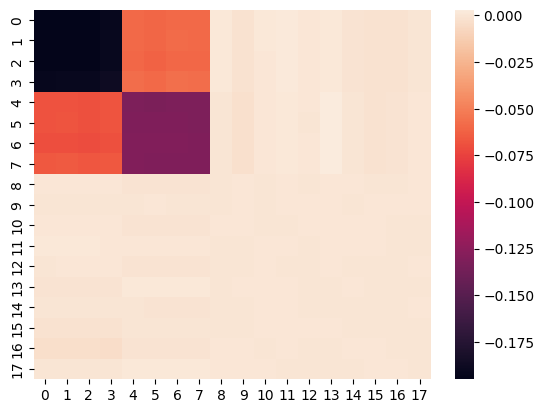

In [23]:
sns.heatmap(st_svd.adjacency)

In [24]:
clustering = ClusteringCPQR(st_svd.adjacency, k=3)

In [25]:
clustering.vkT.shape

(3, 18)

In [26]:
clustering.U.shape

(3, 3)

In [27]:
clustering.transformed.shape

(3, 18)

In [28]:
import pygfx
from wgpu.gui.jupyter import WgpuCanvas

canvas = WgpuCanvas()
renderer = pygfx.WgpuRenderer(target=canvas, blend_mode="weighted_plus")

fig = fpl.Figure(
    cameras="3d", 
    controller_types="orbit", 
    size=(1000, 800),
    renderer=renderer,
    canvas=canvas
)

subplot = fig[0, 0]

subplot.add_scatter(clustering.vkT.T, colors="r", name="vk.T", sizes=15, alpha=0.2)
subplot.add_scatter(clustering.U.T, colors="b", name="U", sizes=15, alpha=0.2)
subplot.add_scatter(clustering.transformed.T, colors="g", name="transform", sizes=15, alpha=0.2)


fig[0, 0].axes.intersection = (0, 0, 0)
fig.canvas.quality = 100
fig.show(sidecar=True)

RFBOutputContext()

/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:245: RuntimeWarning: divide by zero encountered in divide
  screen_full = (ndc_full[:, :2] / ndc_full[:, 3:4]) * half_canvas_size
/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:245: RuntimeWarning: invalid value encountered in divide
  screen_full = (ndc_full[:, :2] / ndc_full[:, 3:4]) * half_canvas_size
/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:257: RuntimeWarning: invalid value encountered in divide
  screen_sel = (ndc_sel[:, :2] / ndc_sel[:, 3:4]) * half_canvas_size
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterOutputContext(children=(JupyterWgpuCanvas(css_height='800px', css_width='1000px'), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt', layout=Layout(width='auto'), style=ButtonStyle(), tooltip='auto-scale scene'), Button(icon='align-center', layout=Layout(width='auto'), style=ButtonStyle(), tooltip='auto-center scene'), ToggleButton(value=True, icon='hand-pointer', layout=Layout(width='auto'), tooltip='panzoom controller'), ToggleButton(value=True, description='1:1', layout=Layout(width='auto'), style=ToggleButtonStyle(font_weight='bold'), tooltip='maintain aspect'), Button(icon='arrow-up', layout=Layout(width='auto'), style=ButtonStyle(), tooltip='y-axis direction'), Button(icon='draw-polygon', layout=Layout(width='auto'), style=ButtonStyle(), tooltip='add PolygonSelector'), ToggleButton(value=False, icon='video', layout=Layout(width='auto'), tooltip='record'), Dropdown(description='Subplots:', layout=Layout(width='200px'), options=('(0, 0)',), value='(0, 0)')))))

In [29]:
from fastplotlib.graphics._axes import Axes

In [30]:
if clustering.k == 2:
    basis_U = np.array([
        [*clustering.U.T[0], 0],
        [*clustering.U.T[1], 0],
        [0., 0., 1.]
    ])

elif clustering.k == 3:
    basis_U = np.array([
        clustering.U.T[0],
        clustering.U.T[1],
        clustering.U.T[2]
    ])

axes_U = Axes(fig[0, 0], intersection=(0, 0, 0), basis=basis_U)
axes_U.colors = ("b", "b", "b")

fig[0, 0].scene.add(axes_U.world_object)
fig[0, 0].add_animations(axes_U.update_using_camera)

fig[0, 0].axes.colors = ("g", "g", "g")

In [31]:
from ipywidgets import IntSlider, Button, VBox

In [32]:
slider_n_components = IntSlider(min=2, max=50, step=1, description="n_components")
slider_n_pixels = IntSlider(min=1, max=15, step=1, description="pixels per component")
slider_noise = IntSlider(min=0, max=30, step=1, description="noise sigma")
slider_n_bg_pixels = IntSlider(min=0, max=100, step=1, description="n background pixels")
slider_k = IntSlider(min=2, max=50, step=1, description="k")
button = Button(description="Update")

iw_movie = fpl.ImageWidget(movie, figure_kwargs={"size": (1200, 600)})
iw_movie.figure.show(maintain_aspect=False)

iw = fpl.ImageWidget(
    [clustering.vkT, clustering.U, clustering.transformed], 
    names=["vk.T", "U", "transform"], 
    figure_shape=(1, 3),
    figure_kwargs={"controller_ids": [[0, 1, 2]], "size": (1200, 350)},
)
iw.cmap = ["bwr", "bwr", "viridis"]
iw.figure.show(maintain_aspect=False)

def update_movie(*args):
    movie = generate_data(
        n_timepoints=1_000, 
        n_components=slider_n_components.value,
        noise=slider_noise.value,
        n_pixels=slider_n_pixels.value,
        n_pixels_bg=slider_n_bg_pixels.value,
    )

    global st_svd
    
    st_svd = SpaceTimeSVD(movie, w=16)
    st_svd.compute()

    iw_movie.set_data(movie)
    iw_movie.figure[0, 0].auto_scale(maintain_aspect=False)

def update_clustering(*args):
    global st_svd
    
    clustering = ClusteringCPQR(st_svd.adjacency, k=slider_k.value)

    iw.set_data([clustering.vkT, clustering.U, clustering.transformed])
    
    for subplot in iw.figure:
        subplot.auto_scale(maintain_aspect=False)

    iw.cmap = ["bwr", "bwr", "viridis"]

sliders = VBox([slider_n_components, slider_n_pixels, slider_noise, slider_n_bg_pixels, button])

button.on_click(update_movie)

button_clustering = Button(description="Update k")
button_clustering.on_click(update_clustering)

VBox([sliders, iw_movie.show(), slider_k, button_clustering, iw.show()])

RFBOutputContext()

RFBOutputContext()

In [33]:
selector_movie = iw_movie.managed_graphics[0].add_linear_selector(axis="y")
selector_vkT = iw.figure["vk.T"]["image_widget_managed"].add_linear_selector(axis="x")
selector_transform = iw.figure["transform"]["image_widget_managed"].add_linear_selector(axis="x")
selectors = [selector_movie, selector_vkT, selector_transform]

In [34]:
class IndexStore:
    def __init__(self):
        self.index: int = None

    def set_index(self, new_index: int, source_graphic: fpl.LinearSelector | fpl.ScatterGraphic):
        self._set_points(new_index)
        self._set_linear_selectors(new_index, source_graphic)

    def _set_points(self, index: int):
        # reset colors
        subplot["vk.T"].colors = (1, 0, 0, 0.2)
        subplot["vk.T"].sizes = 15
        
        subplot["transform"].colors = (0, 1, 0, 0.2)
        subplot["transform"].sizes = 15
        
        # set colors and size
        subplot["vk.T"].colors[index] = "yellow"
        subplot["vk.T"].sizes[index] = 25
        
        subplot["transform"].colors[index] = "cyan"
        subplot["transform"].sizes[index] = 25

    def _set_linear_selectors(self, index: int, source_graphic):
        with fpl.pause_events(*selectors):
            for selector in selectors:
                if source_graphic is selector:
                    continue
                selector.selection = index

    def _scatter_callback(self, ev):
        index = ev.pick_info["vertex_index"]
        self.set_index(index, ev.graphic)
    
    def register_scatter(self, graphic: fpl.ScatterGraphic):
        graphic.add_event_handler(self._scatter_callback, "click")

    def _linear_selector_callback(self, ev):
        index = ev.get_selected_index()
        self.set_index(index, ev.graphic)
    
    def register_linear_selector(self, selector: fpl.LinearSelector):
        selector.add_event_handler(self._linear_selector_callback, "selection")

In [35]:
index_store = IndexStore()

index_store.register_scatter(subplot["vk.T"])
index_store.register_scatter(subplot["transform"])

index_store.register_linear_selector(selector_movie)
index_store.register_linear_selector(selector_vkT)
index_store.register_linear_selector(selector_transform)